# Tutorial 06a — Discover station types with clustering and PCA

We return to the original BART catchment-area data because its four variables and named stations make unsupervised learning tangible. There is no target label: we ask whether stations form interpretable types and which variables separate them.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `06 Unsupervised learning`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "06 Unsupervised learning"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/06 Unsupervised learning


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics. PyTorch builds the neural networks used in this lesson.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("torch", torch.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
torch 2.5.0
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn torch


Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
COLORS = ["#4C78A8", "#F58518", "#54A24B"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

data = pd.read_csv("data_X.csv").iloc[:48].copy()
features = ["TotPop", "AutoOwn0", "TotEmp", "Tot Rd Dens"]

print("Raw station table shape:", data.shape, "= (stations, columns)")
print("The preview and summary below use the original census and road-density units.")
display(data[["Station"] + features].head())
display(data[features].describe().T)

Raw station table shape: (48, 5) = (stations, columns)
The preview and summary below use the original census and road-density units.


,Station,TotPop,AutoOwn0,TotEmp,Tot Rd Dens
0,12TH,11084,1664,33120,42.232657
1,16TH,142973,20505,103479,32.296762
2,19TH,36177,4704,47570,31.822631
3,24TH,104191,8018,39663,32.894203
4,ANTC,70630,1142,13924,20.531431


,count,mean,std,min,25%,50%,75%,max
TotPop,48.0,64938.229167,34334.037554,6743.000000,40006.250000,57065.500000,87707.250000,142973.000000
AutoOwn0,48.0,3687.041667,5700.402404,137.000000,1119.250000,1744.000000,3821.500000,32395.000000
TotEmp,48.0,35374.187500,35404.127357,2577.000000,14383.000000,25595.000000,41383.000000,181995.000000
Tot Rd Dens,48.0,26.257584,6.416346,13.451875,22.224975,25.635289,30.666562,42.232657


![BART system and catchment context](img/BART_Map.png)

The variables use different units, so Euclidean distance on raw values would be dominated by variables with a large numerical spread. Standardisation is therefore part of the model definition.

### How standardisation works

For each feature separately, subtract its mean and divide by its standard deviation:

$$
z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.
$$

After this transformation, every fitted feature has mean approximately 0 and standard deviation approximately 1. For example, $z=2$ means two standard deviations above that feature's mean. `StandardScaler.fit_transform(...)` first learns the mean and standard deviation and then applies the formula. K-means is fitted to these standardized values, but `inverse_transform(...)` converts its centres back to the original population and employment units for interpretation.

,raw mean,raw standard deviation,standardized mean,standardized standard deviation
TotPop,64938.229,33974.509,0.0,1.0
TotEmp,35374.188,35033.393,0.0,1.0


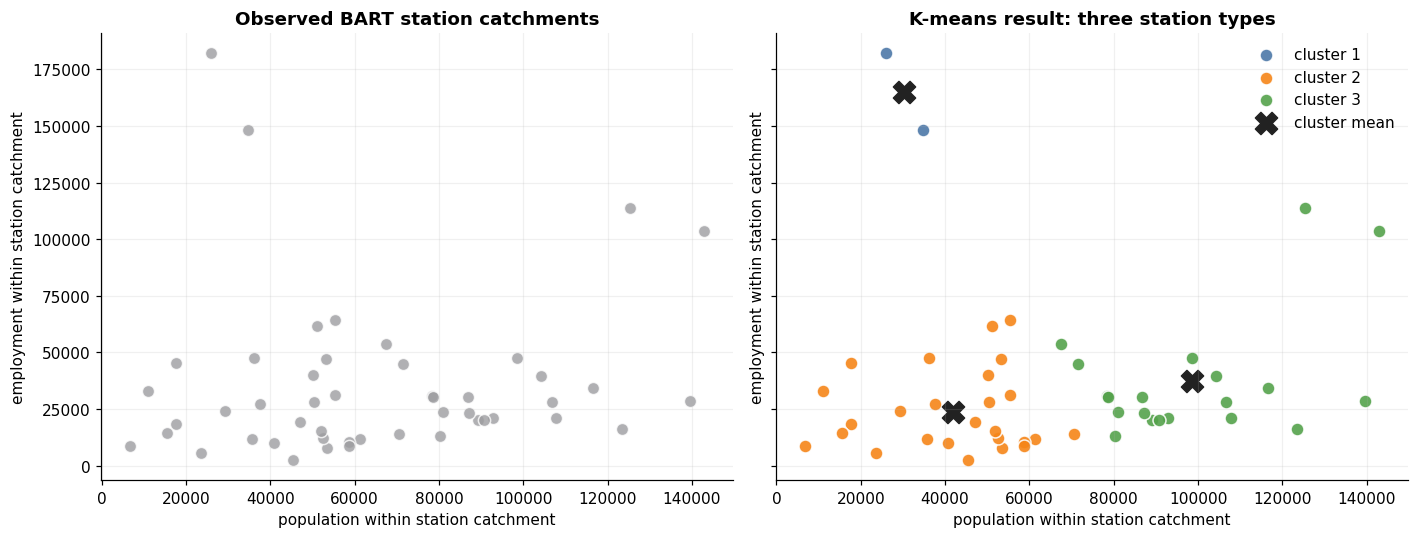

In [5]:
cluster_features = ["TotPop", "TotEmp"]
# K-means uses Euclidean distance, so variables with different numerical scales
# are standardized for fitting only. Plots and cluster centres stay in raw units.
cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(data[cluster_features])
scaling_check = pd.DataFrame({
    "raw mean": data[cluster_features].mean(),
    "raw standard deviation": data[cluster_features].to_numpy().std(axis=0),
    "standardized mean": X_cluster.mean(axis=0),
    "standardized standard deviation": X_cluster.std(axis=0),
}, index=cluster_features)
display(scaling_check.round(3))

kmeans = KMeans(n_clusters=3, n_init=20, random_state=42)
data["cluster"] = kmeans.fit_predict(X_cluster)
centres = cluster_scaler.inverse_transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
axes[0].scatter(
    data["TotPop"],
    data["TotEmp"],
    s=64,
    color="#9D9DA0",
    alpha=0.8,
    edgecolor="white",
)
axes[0].set_title("Observed BART station catchments")

for cluster_id, color in enumerate(COLORS):
    belongs_to_cluster = data["cluster"].eq(cluster_id)
    axes[1].scatter(
        data.loc[belongs_to_cluster, "TotPop"],
        data.loc[belongs_to_cluster, "TotEmp"],
        s=72,
        color=color,
        label=f"cluster {cluster_id + 1}",
        alpha=0.9,
        edgecolor="white",
    )

axes[1].scatter(
    centres[:, 0],
    centres[:, 1],
    s=210,
    marker="X",
    color="#222222",
    label="cluster mean",
)
axes[1].set_title("K-means result: three station types")
axes[1].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("population within station catchment")
    ax.set_ylabel("employment within station catchment")
    ax.grid(alpha=0.18)

plt.tight_layout()
plt.show()

## Read the three clusters as station types

Here $k=3$ is a deliberate teaching choice: it is small enough to inspect, while separating low-, mixed- and high-activity catchments more clearly than a binary split. The numeric labels have no meaning by themselves, so we inspect both cluster profiles and station names. Exercise 06a asks you to test how robust this choice is.

TotPop          TotEmp      
            mean count      mean count
cluster                               
0        30330.0     2  165175.0     2
1        41817.0    26   23923.0    26
2        98457.0    20   37280.0    20

,stations
cluster,
1,"EMBR, MONT"
2,"12TH, 19TH, ANTC, ASHB, CAST, COLM, DBRK, DELN..."
3,"16TH, 24TH, BALB, BAYF, CIVC, COLS, CONC, DALY..."


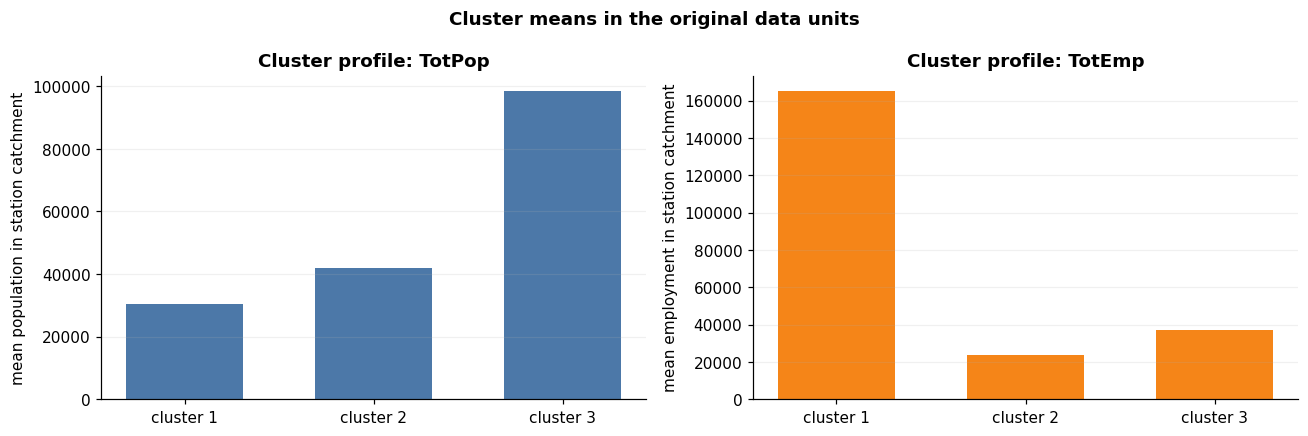

In [6]:
profile = data.groupby("cluster")[cluster_features].agg(["mean", "count"])
display(profile.round(0))

members = (
    data.assign(cluster=data["cluster"] + 1)
    .groupby("cluster")["Station"]
    .apply(lambda station_names: ", ".join(sorted(station_names)))
    .rename("stations")
)
display(members.to_frame())

cluster_means = data.groupby("cluster")[cluster_features].mean()
cluster_labels = [f"cluster {i + 1}" for i in cluster_means.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw_plot_settings = [
    ("TotPop", "mean population in station catchment", COLORS[0]),
    ("TotEmp", "mean employment in station catchment", COLORS[1]),
]
for ax, (feature, ylabel, color) in zip(axes, raw_plot_settings):
    ax.bar(cluster_labels, cluster_means[feature], color=color, width=0.62)
    ax.set_ylabel(ylabel)
    ax.set_title(f"Cluster profile: {feature}")
    ax.grid(axis="y", alpha=0.18)

fig.suptitle("Cluster means in the original data units", fontweight="bold")
plt.tight_layout()

## PCA: a map of feature space

PCA is not clustering. Because the four station variables use different units, scaling is used internally before PCA. It compresses those four variables into a smaller set of linear coordinates while retaining as much variation as possible. PC1 and PC2 are weighted combinations of population, car-free households, employment and road density; the loading table shows those weights. In the PCA map, every point is a station, nearby points have similar four-variable profiles, and colour reuses the K-means cluster found above.

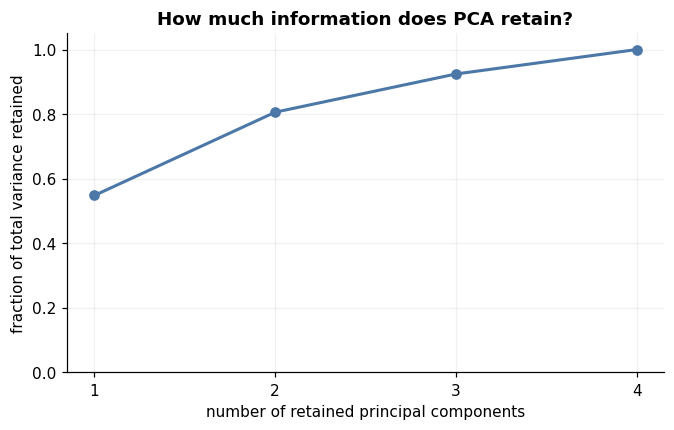

,PC1 loading,PC2 loading
TotPop,0.295,0.851
AutoOwn0,0.588,0.197
TotEmp,0.545,-0.351
Tot Rd Dens,0.519,-0.337


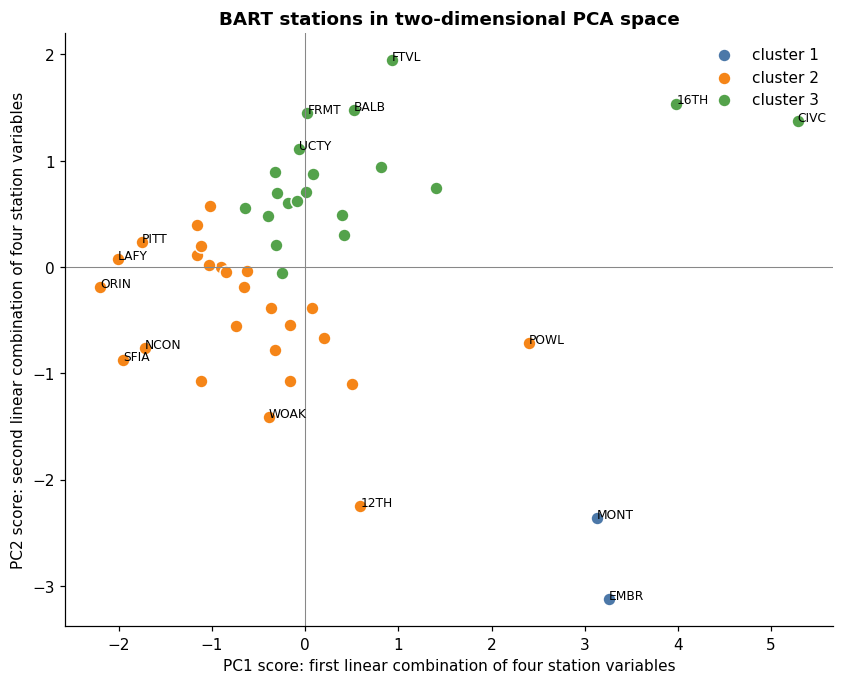

In [7]:
all_feature_scaler = StandardScaler()
X_all = all_feature_scaler.fit_transform(data[features])

pca = PCA()
pca.fit(X_all)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(7, 4))
component_number = np.arange(1, len(features) + 1)
ax.plot(component_number, cumulative_variance, marker="o", color=COLORS[0], linewidth=2)
ax.set_xticks(component_number)
ax.set_ylim(0, 1.05)
ax.set_xlabel("number of retained principal components")
ax.set_ylabel("fraction of total variance retained")
ax.set_title("How much information does PCA retain?")
ax.grid(alpha=0.18)
plt.show()

pca_scores = pca.transform(X_all)
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=features,
    columns=["PC1 loading", "PC2 loading"],
)
display(loadings.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
for cluster_id, color in enumerate(COLORS):
    belongs_to_cluster = data["cluster"].eq(cluster_id)
    ax.scatter(
        pca_scores[belongs_to_cluster, 0],
        pca_scores[belongs_to_cluster, 1],
        color=color,
        s=72,
        label=f"cluster {cluster_id + 1}",
        edgecolor="white",
    )

pc1_label_threshold = np.quantile(np.abs(pca_scores[:, 0]), 0.8)
pc2_label_threshold = np.quantile(np.abs(pca_scores[:, 1]), 0.8)
for station_id, row in data.iterrows():
    is_extreme = (
        abs(pca_scores[station_id, 0]) > pc1_label_threshold
        or abs(pca_scores[station_id, 1]) > pc2_label_threshold
    )
    if is_extreme:
        ax.annotate(row["Station"], pca_scores[station_id, :2], fontsize=8)

ax.axhline(0, color="#888888", linewidth=0.7)
ax.axvline(0, color="#888888", linewidth=0.7)
ax.set_xlabel("PC1 score: first linear combination of four station variables")
ax.set_ylabel("PC2 score: second linear combination of four station variables")
ax.set_title("BART stations in two-dimensional PCA space")
ax.legend(frameon=False)
plt.show()

In [8]:
station_results = (
    data.assign(cluster=data["cluster"] + 1)
    .sort_values(["cluster", "TotEmp"])
    [["Station", "cluster"] + features]
    .reset_index(drop=True)
)
display(station_results)
print("A cluster becomes useful only after we connect its profile to named stations and a practical interpretation.")

,Station,cluster,TotPop,AutoOwn0,TotEmp,Tot Rd Dens
0,MONT,1,34689,9443,148355,38.906830
1,EMBR,1,25970,5383,181995,40.153692
2,PITT,2,45490,680,2577,16.945628
3,ORIN,2,23534,334,5417,13.722529
4,DELN,2,53456,1454,8027,24.479480
5,WARM,2,58684,385,8763,22.536521
6,SFIA,2,6743,162,8855,18.039045
7,PLZA,2,40792,859,10002,28.217755
8,COLM,2,58683,1272,10580,27.037100
9,LAFY,2,35785,412,11766,13.451875


A cluster becomes useful only after we connect its profile to named stations and a practical interpretation.
